In [103]:
#importing all libraries 
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
# connecting to mysql to import both tables
import mysql.connector

In [9]:
mydb = mysql.connector.connect(
    host="localhost",
    user="root",
    password="Sattu@123",
    database="credit_risk"
)
if mydb.is_connected():
    print("MySQL connected successfully!")

MySQL connected successfully!


In [18]:
# loading customers table in python
customers_df = pd.read_sql("SELECT * FROM customers",mydb)
# loading loans tables in python 
loans_df = pd.read_sql("SELECT * FROM loans",mydb)
print("Both tables successfully loaded")

C:\Users\Mahakal Enterprises\AppData\Local\Temp\ipykernel_11136\831753386.py:2: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  customers_df = pd.read_sql(
C:\Users\Mahakal Enterprises\AppData\Local\Temp\ipykernel_11136\831753386.py:8: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  loans_df = pd.read_sql(


Both tables successfully load


In [19]:
print(f"Customers:", customers_df.shape)
print(f"loans:", loans_df.shape)

Customers: (18000, 8)
loans: (30000, 14)


In [21]:
print(customers_df.columns.tolist())
print(loans_df.columns.tolist())

['customer_id', 'age', 'employment_type', 'education_level', 'annual_income', 'credit_score', 'region', 'customer_since']
['loan_id', 'customer_id', 'loan_purpose', 'loan_amount', 'interest_rate', 'term_months', 'issue_date', 'debt_to_income_pct', 'delinquency_count', 'monthly_payment', 'total_paid_to_date', 'outstanding_balance', 'loan_status', 'default_flag']


In [22]:
credit_risk_df = pd.merge(
    loans_df,
    customers_df,
    on="customer_id",
    how="left"
)

In [25]:
credit_risk_df.isnull().sum()

loan_id                 0
customer_id             0
loan_purpose            0
loan_amount             0
interest_rate           0
term_months             0
issue_date              0
debt_to_income_pct      0
delinquency_count       0
monthly_payment         0
total_paid_to_date      0
outstanding_balance     0
loan_status             0
default_flag            0
age                     0
employment_type         0
education_level         0
annual_income          72
credit_score            0
region                  0
customer_since          0
dtype: int64

In [26]:
print("Loans shape:", loans_df.shape)
print("Customers shape:", customers_df.shape)
print("Combined data shape:", credit_risk_df.shape)

Loans shape: (30000, 14)
Customers shape: (18000, 8)
Combined data shape: (30000, 21)


In [27]:
customers_df["customer_id"].is_unique

True

In [28]:
print("Loans rows:", len(loans_df))
print("Combined rows:", len(credit_risk_df))

Loans rows: 30000
Combined rows: 30000


In [29]:
# Dataset ka size
print("Dataset Shape:", credit_risk_df.shape)

# Columns ki information
print("\nColumn Information:")
credit_risk_df.info()

Dataset Shape: (30000, 21)

Column Information:
<class 'pandas.DataFrame'>
RangeIndex: 30000 entries, 0 to 29999
Data columns (total 21 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   loan_id              30000 non-null  str    
 1   customer_id          30000 non-null  str    
 2   loan_purpose         30000 non-null  str    
 3   loan_amount          30000 non-null  float64
 4   interest_rate        30000 non-null  float64
 5   term_months          30000 non-null  int64  
 6   issue_date           30000 non-null  object 
 7   debt_to_income_pct   30000 non-null  float64
 8   delinquency_count    30000 non-null  int64  
 9   monthly_payment      30000 non-null  float64
 10  total_paid_to_date   30000 non-null  float64
 11  outstanding_balance  30000 non-null  float64
 12  loan_status          30000 non-null  str    
 13  default_flag         30000 non-null  int64  
 14  age                  30000 non-null  int64  
 15 

# Most of the data already cleaned but annual income remains 72 nulls 

In [30]:
# To check missing values in every columns
missing_values = credit_risk_df.isnull().sum()

print(missing_values[missing_values > 0].sort_values(ascending=False))

annual_income    72
dtype: int64


In [31]:
print("Customers mein NULL annual income:",
      customers_df["annual_income"].isnull().sum())

print("Combined dataset mein NULL annual income:",
      credit_risk_df["annual_income"].isnull().sum())

Customers mein NULL annual income: 45
Combined dataset mein NULL annual income: 72


In [32]:
# Check whether every loan has a matching customer
customer_match = loans_df["customer_id"].isin(
    customers_df["customer_id"]
)

print("Total loans:", len(loans_df))
print("Loans with matching customers:", customer_match.sum())
print("Loans without matching customers:", (~customer_match).sum())

Total loans: 30000
Loans with matching customers: 30000
Loans without matching customers: 0


In [33]:
print("Duplicate rows:", credit_risk_df.duplicated().sum())

Duplicate rows: 0


In [ ]:
print(credit_risk_df.dtypes)
print("\nTotal missing values:", credit_risk_df.isnull().sum().sum())

# EDA(Explorartory data analysis) has started from here 

In [35]:
# Total number of loans
total_loans = len(credit_risk_df)

# Total loan amount
total_loan_amount = credit_risk_df["loan_amount"].sum()

# Total defaulted loans
total_defaults = (credit_risk_df["default_flag"] == 1).sum()

# Default rate in percentage
default_rate = (
    total_defaults / total_loans
) * 100

# Average loan amount
average_loan_amount = credit_risk_df["loan_amount"].mean()

# Display results
print("===== LOAN PORTFOLIO ANALYSIS =====")
print(f"Total Loans: {total_loans:,}")
print(f"Total Loan Amount: {total_loan_amount:,.2f}")
print(f"Total Defaults: {total_defaults:,}")
print(f"Default Rate: {default_rate:.2f}%")
print(f"Average Loan Amount: {average_loan_amount:,.2f}")

===== LOAN PORTFOLIO ANALYSIS =====
Total Loans: 30,000
Total Loan Amount: 12,741,023,300.00
Total Defaults: 1,466
Default Rate: 4.89%
Average Loan Amount: 424,700.78


In [37]:
credit_risk_df.nunique()

loan_id                30000
customer_id            18000
loan_purpose               7
loan_amount             8973
interest_rate           1327
term_months                5
issue_date              1825
debt_to_income_pct       654
delinquency_count          8
monthly_payment        29578
total_paid_to_date     21906
outstanding_balance    29982
loan_status                4
default_flag               2
age                       50
employment_type            5
education_level            5
annual_income          17846
credit_score             426
region                     5
customer_since          3958
dtype: int64

In [40]:
credit_risk_df.columns.tolist()

['loan_id',
 'customer_id',
 'loan_purpose',
 'loan_amount',
 'interest_rate',
 'term_months',
 'issue_date',
 'debt_to_income_pct',
 'delinquency_count',
 'monthly_payment',
 'total_paid_to_date',
 'outstanding_balance',
 'loan_status',
 'default_flag',
 'age',
 'employment_type',
 'education_level',
 'annual_income',
 'credit_score',
 'region',
 'customer_since',
 'credit_score_category']

In [39]:
# Create credit score categories
credit_risk_df["credit_score_category"] = pd.cut(
    credit_risk_df["credit_score"],
    bins=[-float("inf"), 579, 669, float("inf")],
    labels=["Poor", "Fair", "Good"]
)

credit_risk_df[["credit_score", "credit_score_category"]].head(10)

,credit_score,credit_score_category
0,631,Fair
1,775,Good
2,659,Fair
3,697,Good
4,688,Good
5,569,Poor
6,479,Poor
7,682,Good
8,798,Good
9,676,Good


In [41]:
# Group data by credit score category
credit_score_analysis = credit_risk_df.groupby("credit_score_category",observed=False).agg(
    total_loans=("loan_id", "count"),
    defaulted_loans=("default_flag", "sum"))

# Calculate default rate
credit_score_analysis["default_rate_pct"] = (credit_score_analysis["defaulted_loans"]/ credit_score_analysis["total_loans"]) * 100
# Display results
credit_score_analysis["default_rate_pct"] = (credit_score_analysis["default_rate_pct"].round(2))
credit_score_analysis

,total_loans,defaulted_loans,default_rate_pct
credit_score_category,,,
Poor,4137,540,13.05
Fair,11891,610,5.13
Good,13972,316,2.26


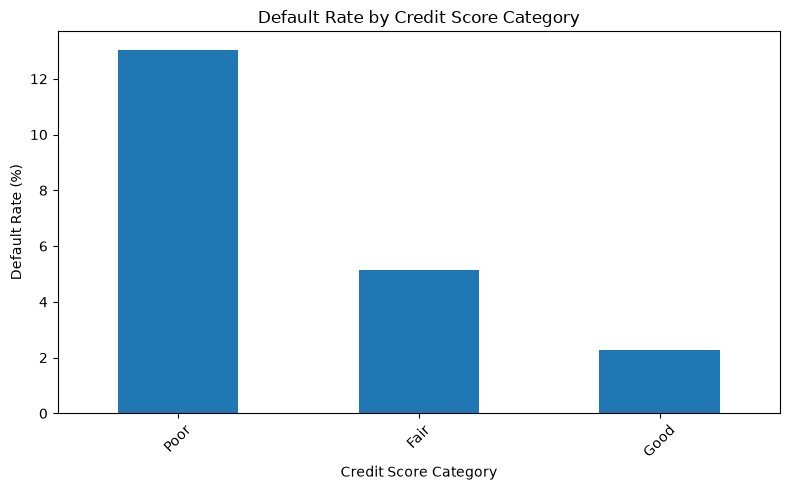

In [43]:
credit_score_analysis["default_rate_pct"].plot(
    kind="bar",
    figsize=(8, 5)
)
plt.title("Default Rate by Credit Score Category")
plt.xlabel("Credit Score Category")
plt.ylabel("Default Rate (%)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Key Insight: Customers with poor credit scores exhibited a 13.05% loan default rate, compared with 2.26% among customers with good credit scores.
This indicates a strong association between lower credit scores and higher default risk in the analysed dataset.

Recommendation: The bank should consider additional risk assessment and repayment-capacity
checks for applicants with poor credit scores rather than relying on credit score alone.

In [44]:
# default rate by loan_purpose analysis
loan_purpose_analysis = credit_risk_df.groupby( "loan_purpose").agg(
    total_loans=("loan_id", "count"),
    defaulted_loans=("default_flag", "sum"))
loan_purpose_analysis["default_rate_pct"] = ( loan_purpose_analysis["defaulted_loans"]/ loan_purpose_analysis["total_loans"]) * 100
loan_purpose_analysis["default_rate_pct"] = (loan_purpose_analysis["default_rate_pct"].round(2))

loan_purpose_analysis = loan_purpose_analysis.sort_values(by="default_rate_pct",ascending=False)
loan_purpose_analysis

,total_loans,defaulted_loans,default_rate_pct
loan_purpose,,,
Small Business,3025,171,5.65
Personal,4293,235,5.47
Debt Consolidation,7472,394,5.27
Home Improvement,4791,224,4.68
Medical,2996,133,4.44
Education,3242,137,4.23
Auto,4181,172,4.11


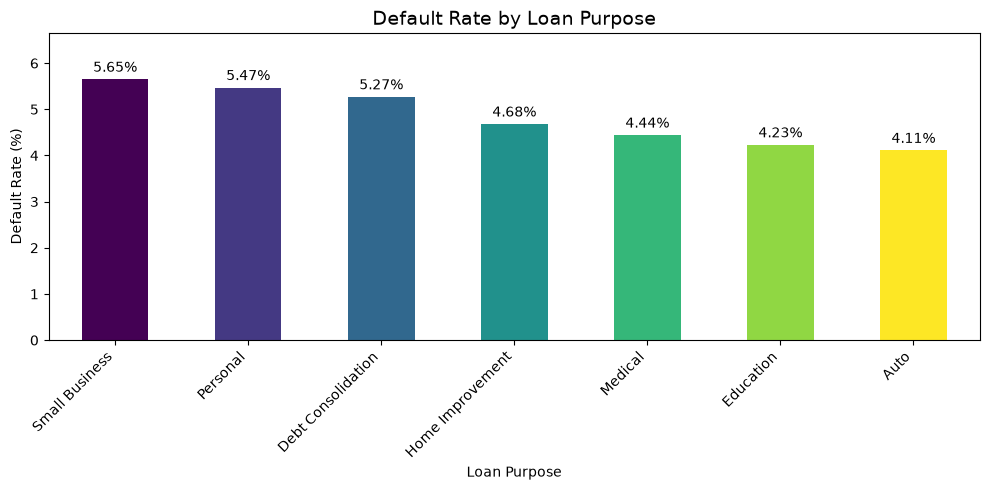

In [48]:
ax = loan_purpose_analysis["default_rate_pct"].plot(kind="bar",figsize=(10, 5),
    color=plt.cm.viridis(
        [i / (len(loan_purpose_analysis) - 1)
         for i in range(len(loan_purpose_analysis))]
    ))

# Show values above each bar
for container in ax.containers:
    ax.bar_label(container, fmt="%.2f%%", padding=3)

plt.title("Default Rate by Loan Purpose", fontsize=14)
plt.xlabel("Loan Purpose")
plt.ylabel("Default Rate (%)")
plt.xticks(rotation=45, ha="right")
plt.ylim(0, loan_purpose_analysis["default_rate_pct"].max() + 1)
plt.tight_layout()
plt.show()

In [49]:
credit_risk_df["loan_amount"].describe()

count    3.000000e+04
mean     4.247008e+05
std      2.884639e+05
min      2.500000e+04
25%      2.305000e+05
50%      3.520000e+05
75%      5.335250e+05
max      2.500000e+06
Name: loan_amount, dtype: float64

In [50]:
# default rate by loan amount 
credit_risk_df["loan_amount_category"] = pd.cut(
    credit_risk_df["loan_amount"],
    bins=[0, 250000, 500000, 1000000, float("inf")],
    labels=[
        "Low (<=250K)",
        "Medium (250K-500K)",
        "High (500K-1M)",
        "Very High (>1M)"
    ],
    include_lowest=True
)

In [51]:
loan_amount_analysis = credit_risk_df.groupby( "loan_amount_category",observed=False).agg(
    total_loans=("loan_id", "count"),
    defaulted_loans=("default_flag", "sum"))

loan_amount_analysis["default_rate_pct"] = (loan_amount_analysis["defaulted_loans"]/ loan_amount_analysis["total_loans"] * 100).round(2)

loan_amount_analysis

,total_loans,defaulted_loans,default_rate_pct
loan_amount_category,,,
Low (<=250K),8789,434,4.94
Medium (250K-500K),12719,640,5.03
High (500K-1M),7147,325,4.55
Very High (>1M),1345,67,4.98


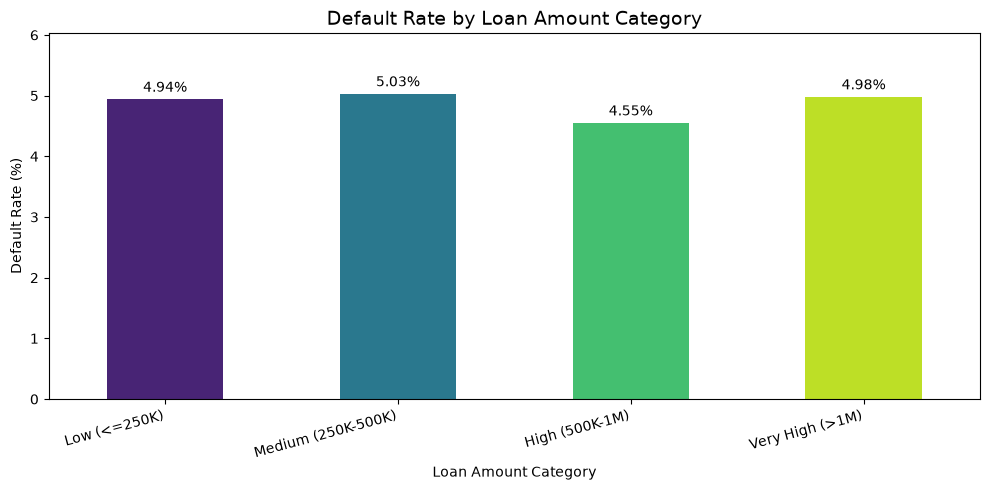

In [52]:
ax = loan_amount_analysis["default_rate_pct"].plot(kind="bar",figsize=(10, 5),color=plt.cm.viridis([0.1, 0.4, 0.7, 0.9]))

# Show percentage labels on bars
for container in ax.containers:
    ax.bar_label(container, fmt="%.2f%%", padding=3)

plt.title("Default Rate by Loan Amount Category", fontsize=14)
plt.xlabel("Loan Amount Category")
plt.ylabel("Default Rate (%)")
plt.xticks(rotation=15, ha="right")
plt.ylim(0, loan_amount_analysis["default_rate_pct"].max() + 1)
plt.tight_layout()
plt.show()

In [53]:
# Default rate by interest rate 
credit_risk_df["interest_rate_category"] = pd.cut(
    credit_risk_df["interest_rate"],
    bins=[0, 10, 15, 20, float("inf")],
    labels=[
        "Below 10%",
        "10%-15%",
        "15%-20%",
        "20% and Above"
    ],
    include_lowest=True
)

In [54]:
interest_rate_analysis = credit_risk_df.groupby( "interest_rate_category",observed=False
).agg(
    total_loans=("loan_id", "count"),
    defaulted_loans=("default_flag", "sum"))

interest_rate_analysis["default_rate_pct"] = (interest_rate_analysis["defaulted_loans"]/ interest_rate_analysis["total_loans"] * 100).round(2)

interest_rate_analysis

,total_loans,defaulted_loans,default_rate_pct
interest_rate_category,,,
Below 10%,17673,481,2.72
10%-15%,11074,779,7.03
15%-20%,1235,201,16.28
20% and Above,18,5,27.78


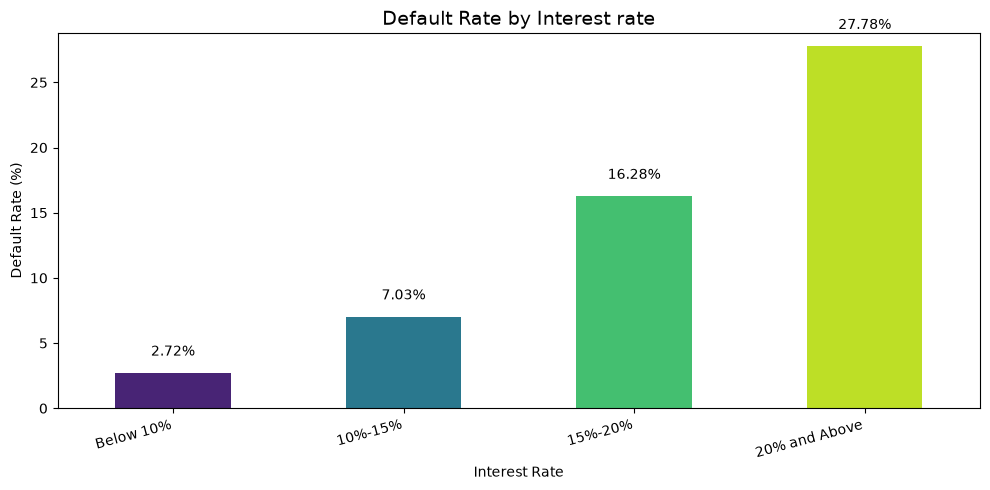

In [64]:
ax = interest_rate_analysis["default_rate_pct"].plot(kind="bar",figsize=(10, 5),color=plt.cm.viridis([0.1, 0.4, 0.7, 0.9]))

# Show percentage labels on bars
for container in ax.containers:
    ax.bar_label(container, fmt="%.2f%%", padding=10)

plt.title("Default Rate by Interest rate", fontsize=14)
plt.xlabel("Interest Rate")
plt.ylabel("Default Rate (%)")
plt.xticks(rotation=15, ha="right")
plt.ylim(0, interest_rate_analysis["default_rate_pct"].max() + 1)
plt.tight_layout()
plt.show()

In [65]:
credit_risk_df["debt_to_income_pct"].describe()

count    30000.000000
mean        29.477630
std         11.371709
min          0.000000
25%         21.800000
50%         29.500000
75%         37.100000
max         75.000000
Name: debt_to_income_pct, dtype: float64

In [67]:
credit_risk_df["dti_category"] = pd.cut(
    credit_risk_df["debt_to_income_pct"],
    bins=[-float("inf"), 20, 35, 50, float("inf")],
    labels=["Low (<=20%)", "Medium (20-35%)",
            "High (35-50%)", "Very High (>50%)"],
    include_lowest=True
)

In [68]:
dti_analysis = credit_risk_df.groupby("dti_category",observed=False
).agg(
    total_loans=("loan_id", "count"),
    defaulted_loans=("default_flag", "sum"))

dti_analysis["default_rate_pct"] = (dti_analysis["defaulted_loans"] / dti_analysis["total_loans"] * 100
).round(2)

dti_analysis

,total_loans,defaulted_loans,default_rate_pct
dti_category,,,
Low (<=20%),6127,173,2.82
Medium (20-35%),14510,637,4.39
High (35-50%),8293,553,6.67
Very High (>50%),1070,103,9.63


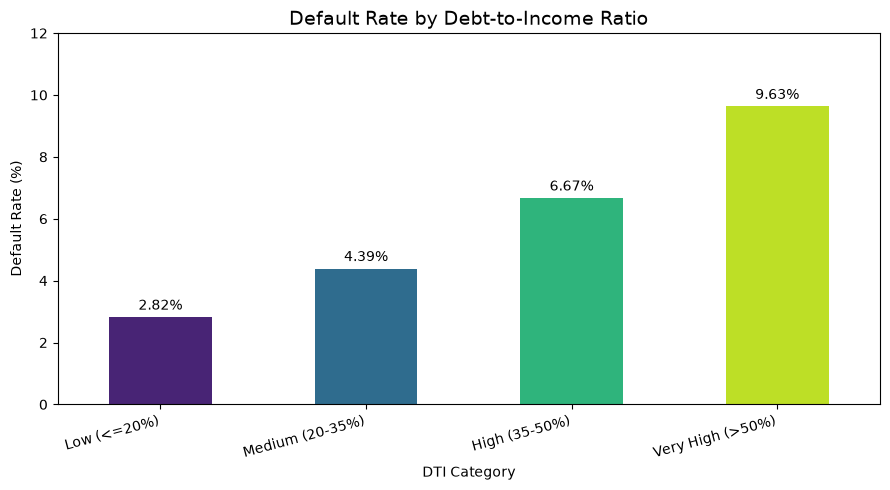

In [69]:
ax = dti_analysis["default_rate_pct"].plot(
    kind="bar",
    figsize=(9, 5),
    color=plt.cm.viridis([0.1, 0.35, 0.65, 0.9])
)
for container in ax.containers:
    ax.bar_label(container, fmt="%.2f%%", padding=3)

plt.title("Default Rate by Debt-to-Income Ratio", fontsize=14)
plt.xlabel("DTI Category")
plt.ylabel("Default Rate (%)")
plt.xticks(rotation=15, ha="right")
plt.ylim(0, 12)
plt.tight_layout()
plt.show()

#Business Insight:

The analysis shows a clear positive relationship between the debt-to-income (DTI) ratio and loan default rates. 
Borrowers with a DTI above 50% have the highest default rate at 9.63%, compared with just 2.82% for borrowers with a DTI of 20% or less. 
This indicates that borrowers with higher debt obligations relative to their income may face greater repayment difficulties.

Business Recommendation: Lenders should consider implementing stricter affordability assessments for high-DTI applicants, evaluating their existing 
debt obligations and repayment capacity before approving loans. DTI should also be assessed alongside credit scores, income levels,
and repayment history to support more informed lending decisions.

In [70]:
credit_risk_df["delinquency_count"].describe()

count    30000.000000
mean         0.463433
std          0.751320
min          0.000000
25%          0.000000
50%          0.000000
75%          1.000000
max          7.000000
Name: delinquency_count, dtype: float64

In [71]:
credit_risk_df["delinquency_category"] = pd.cut(
    credit_risk_df["delinquency_count"],
    bins=[-1, 0, 1, 2, float("inf")],
    labels=[
        "No Delinquencies",
        "1 Delinquency",
        "2 Delinquencies",
        "3+ Delinquencies"
    ]
)

In [72]:
delinquency_analysis = credit_risk_df.groupby(
    "delinquency_category",
    observed=False
).agg(
    total_loans=("loan_id", "count"),
    defaulted_loans=("default_flag", "sum")
)

delinquency_analysis["default_rate_pct"] = (
    delinquency_analysis["defaulted_loans"]
    / delinquency_analysis["total_loans"] * 100
).round(2)

delinquency_analysis

,total_loans,defaulted_loans,default_rate_pct
delinquency_category,,,
No Delinquencies,19597,262,1.34
1 Delinquency,7820,418,5.35
2 Delinquencies,1911,389,20.36
3+ Delinquencies,672,397,59.08


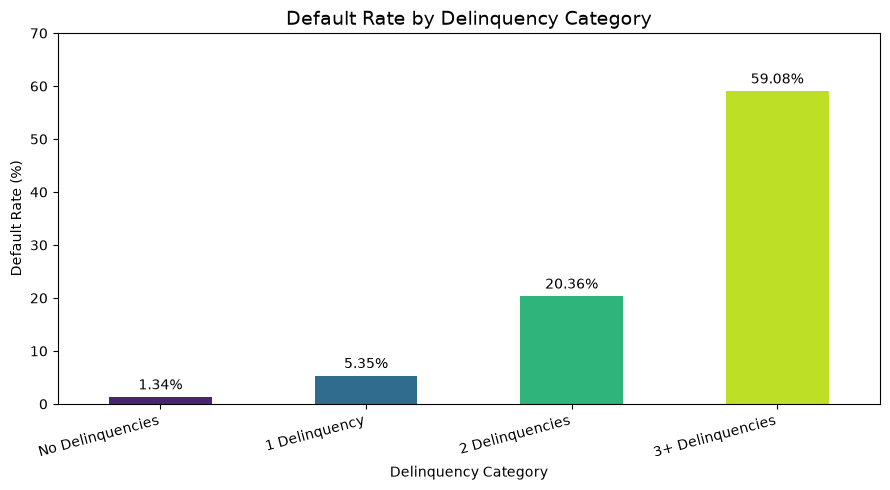

In [73]:
ax = delinquency_analysis["default_rate_pct"].plot(
    kind="bar",
    figsize=(9, 5),
    color=plt.cm.viridis([0.1, 0.35, 0.65, 0.9])
)

for container in ax.containers:
    ax.bar_label(container, fmt="%.2f%%", padding=3)

plt.title("Default Rate by Delinquency Category", fontsize=14)
plt.xlabel("Delinquency Category")
plt.ylabel("Default Rate (%)")
plt.xticks(rotation=15, ha="right")
plt.ylim(0, 70)
plt.tight_layout()
plt.show()

# Key Business Insights
No Delinquencies: This group has the lowest default rate at 1.34%, indicating a comparatively lower-risk segment.
1 Delinquency: The default rate increases to 5.35%, suggesting that even one past delinquency may be a useful risk indicator.
2 Delinquencies: The default rate rises sharply to 20.36%, indicating substantially higher repayment risk.
3+ Delinquencies: This group has the highest default rate at 59.08%. Although it contains only 672 loans, nearly 6 out of 10 loans in this 
category defaulted.
    
==> Business Recommendation

Lenders should incorporate delinquency history into their credit risk assessment models.
Applicants with multiple past delinquencies should receive enhanced credit reviews and repayment-capacity assessments. 
Borrowers without delinquencies may qualify for a more streamlined assessment, subject to other creditworthiness checks.

In [74]:
credit_risk_df["employment_type"].value_counts(dropna=False)

employment_type
Salaried          16075
Self-Employed      5985
Business Owner     3822
Contract           2928
Retired            1190
Name: count, dtype: int64

In [75]:
employment_analysis = credit_risk_df.groupby("employment_type",dropna=False
).agg(
    total_loans=("loan_id", "count"),
    defaulted_loans=("default_flag", "sum"))

employment_analysis["default_rate_pct"] = (employment_analysis["defaulted_loans"] / employment_analysis["total_loans"] * 100).round(2)

employment_analysis.sort_values(by="default_rate_pct",ascending=False)

,total_loans,defaulted_loans,default_rate_pct
employment_type,,,
Contract,2928,192,6.56
Retired,1190,75,6.30
Business Owner,3822,205,5.36
Self-Employed,5985,292,4.88
Salaried,16075,702,4.37


#Business Insight:-

Contract Employees: Have the highest default rate at 6.56%, suggesting that income stability may be an important factor to assess.
Retired Borrowers: Show a 6.30% default rate. Lenders should evaluate retirement income and repayment capacity.
Business Owners: Have a default rate of 5.36%. Assessing business income stability and cash flow may help evaluate repayment risk.
Self-Employed Borrowers: Have a default rate of 4.88%. Income variability and financial documentation should be considered during assessment.
Salaried Borrowers: Have the lowest default rate at 4.37% and the largest loan volume, accounting for 16,075 loans.

Business Recommendation: Lenders should consider employment type alongside income stability, credit score, DTI,
and delinquency history when assessing credit risk.Employment type alone should not determine loan approval or rejection.

In [76]:
credit_risk_df["age"].describe()

count    30000.000000
mean        39.243700
std         10.529476
min         21.000000
25%         32.000000
50%         39.000000
75%         46.000000
max         70.000000
Name: age, dtype: float64

In [78]:
bins = [20, 25, 35, 45, 55, 70]
labels = ["21-25", "26-35", "36-45", "46-55", "56-70"]

credit_risk_df["age_group"] = pd.cut(
    credit_risk_df["age"],
    bins=bins,
    labels=labels,
    include_lowest=True
)

credit_risk_df[["age", "age_group"]].head()

,age,age_group
0,26,26-35
1,34,26-35
2,47,46-55
3,41,36-45
4,52,46-55


In [79]:
age_analysis = credit_risk_df.groupby("age_group", observed=False).agg(
    total_loans=("default_flag", "count"),
    defaulted_loans=("default_flag", "sum")
)

age_analysis["default_rate_pct"] = (age_analysis["defaulted_loans"] / age_analysis["total_loans"] * 100).round(2)

age_analysis

,total_loans,defaulted_loans,default_rate_pct
age_group,,,
21-25,3289,169,5.14
26-35,7956,382,4.80
36-45,10594,530,5.00
46-55,6079,292,4.80
56-70,2082,93,4.47


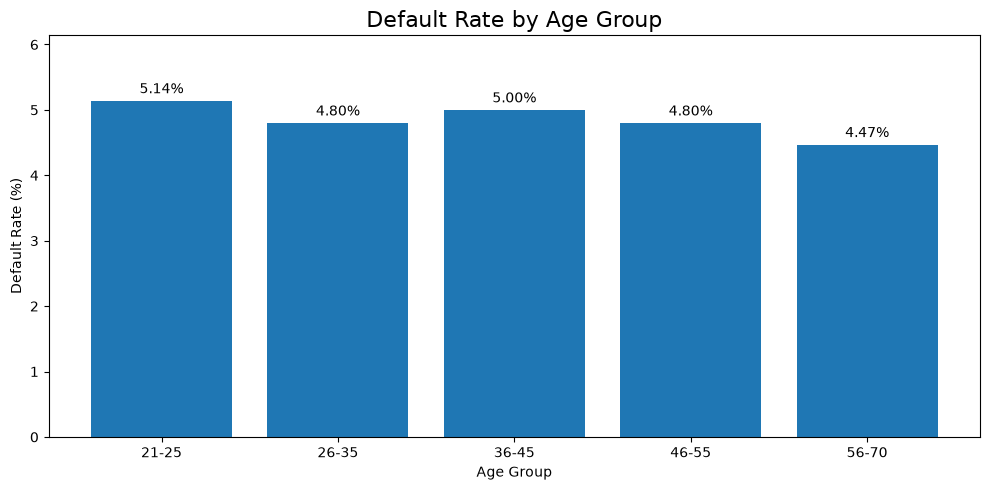

In [80]:
plt.figure(figsize=(10, 5))
ax = plt.bar(age_analysis.index.astype(str),age_analysis["default_rate_pct"])

plt.title("Default Rate by Age Group", fontsize=16)
plt.xlabel("Age Group")
plt.ylabel("Default Rate (%)")

plt.bar_label(ax, fmt="%.2f%%", padding=3)

plt.ylim(0, age_analysis["default_rate_pct"].max() + 1)
plt.tight_layout()
plt.show()

Key Findings:-

1.Young borrowers (21–25 years) have the highest default rate at 5.14%, suggesting a potentially higher risk profile within this segment.
2.Borrowers aged 56–70 years have the lowest default rate at 4.47%, approximately 0.67 percentage points lower than the youngest group.
3.Borrowers aged 36–45 years represent the largest segment, with 10,594 loans and a default rate of 5.00%.

Overall, the relatively small variation in default rates suggests that age alone may have limited predictive value 
for identifying loan defaults in this portfolio.

Recommended Actions:

1. Strengthen Risk Assessment for Younger Borrowers: Evaluate borrowers aged 21–25 using additional indicators such as credit history, income stability, and existing debt obligations rather than applying stricter rules based on age alone.
2. Adopt a Multi-Factor Credit Risk Model: Combine age with credit score, debt-to-income ratio, delinquency history, and interest rate to improve default-risk identification.
3. Prioritize Evidence-Based Lending Decisions: Since default rates vary by only 0.67 percentage points across age groups, avoid using age as the primary factor for approving or rejecting loans.
4. Monitor Default Trends Across Age Segments: Track default rates periodically to identify meaningful changes in risk patterns and validate whether age provides additional predictive value.


In [83]:
credit_risk_df["customer_since"].head()

0   2019-09-20
1   2017-05-18
2   2016-04-12
3   2019-08-28
4   2020-10-23
Name: customer_since, dtype: datetime64[s]

In [84]:
credit_risk_df["issue_date"] = pd.to_datetime(
    credit_risk_df["issue_date"]
)

credit_risk_df["customer_tenure_years"] = (
    (credit_risk_df["issue_date"] - credit_risk_df["customer_since"]).dt.days / 365.25
).round(2)

credit_risk_df[[
    "customer_since",
    "issue_date",
    "customer_tenure_years"
]].head()

,customer_since,issue_date,customer_tenure_years
0,2019-09-20,2021-01-13,1.32
1,2017-05-18,2024-10-25,7.44
2,2016-04-12,2025-04-15,9.01
3,2019-08-28,2023-12-21,4.31
4,2020-10-23,2022-03-05,1.36


In [85]:
bins = [0, 2, 5, 8, float("inf")]

labels = [
    "New Customer (0-2 years)",
    "Established (2-5 years)",
    "Long-Term (5-8 years)",
    "Loyal Customer (8+ years)"
]

credit_risk_df["tenure_group"] = pd.cut(
    credit_risk_df["customer_tenure_years"],
    bins=bins,
    labels=labels,
    include_lowest=True
)

credit_risk_df[[
    "customer_tenure_years",
    "tenure_group"
]].head()

,customer_tenure_years,tenure_group
0,1.32,New Customer (0-2 years)
1,7.44,Long-Term (5-8 years)
2,9.01,Loyal Customer (8+ years)
3,4.31,Established (2-5 years)
4,1.36,New Customer (0-2 years)


In [86]:
tenure_analysis = credit_risk_df.groupby("tenure_group", observed=False
).agg(
    total_loans=("default_flag", "count"),
    defaulted_loans=("default_flag", "sum")
)

tenure_analysis["default_rate_pct"] = (tenure_analysis["defaulted_loans"] / tenure_analysis["total_loans"] * 100
).round(2)

tenure_analysis

,total_loans,defaulted_loans,default_rate_pct
tenure_group,,,
New Customer (0-2 years),5481,261,4.76
Established (2-5 years),7983,393,4.92
Long-Term (5-8 years),7152,347,4.85
Loyal Customer (8+ years),2580,111,4.30


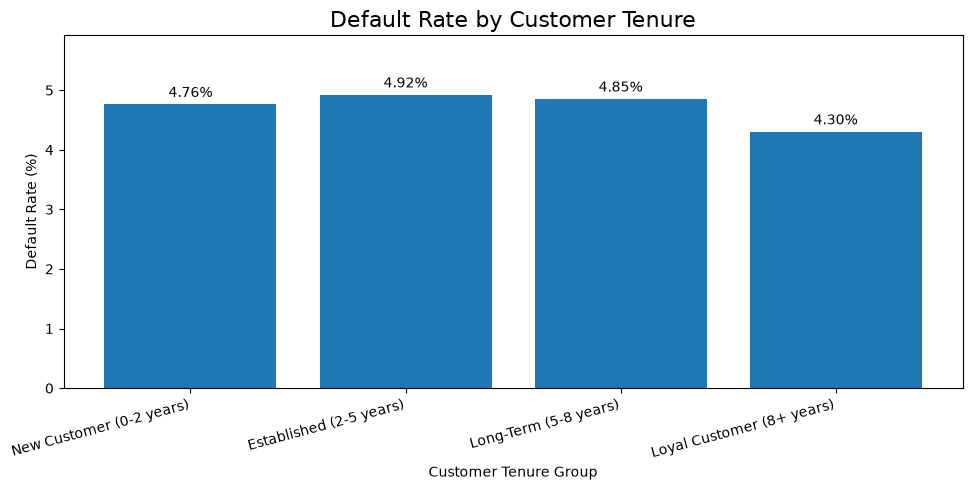

In [87]:
plt.figure(figsize=(10, 5))

bars = plt.bar(
    tenure_analysis.index.astype(str),
    tenure_analysis["default_rate_pct"]
)

plt.title("Default Rate by Customer Tenure", fontsize=16)
plt.xlabel("Customer Tenure Group")
plt.ylabel("Default Rate (%)")

plt.bar_label(bars, fmt="%.2f%%", padding=3)

plt.ylim(0, tenure_analysis["default_rate_pct"].max() + 1)
plt.xticks(rotation=15, ha="right")
plt.tight_layout()
plt.show()

### Key Findings

The analysis indicates that loan default rates are relatively consistent across customer tenure groups, ranging from 4.30% to 4.92%.

* **Established customers (2–5 years)** have the highest default rate at **4.92%**, followed closely by long-term customers (5–8 years) at 4.85%.
* **Loyal customers (8+ years)** have the lowest default rate at **4.30%**, approximately 0.62 percentage points lower than established customers.
* **Established customers** also represent the largest group in this analysis, with 7,983 loans and 393 defaults.
* New customers have a default rate of 4.76%, indicating that recently established relationships do not necessarily correspond to substantially higher default risk.

**Conclusion:** Longer customer relationships may be associated with slightly lower default rates, particularly among customers with more than eight years of tenure., 
the small differences across groups suggest that tenure alone is not a strong standalone indicator of credit risk.

    ### Recommended Actions

1. **Develop Customer Retention Strategies:** Maintain strong relationships with long-standing customers through suitable loan products and responsible credit-limit reviews.

2. **Monitor Established Customers:** Since the 2–5-year tenure group has the highest default rate, review this segment alongside credit score, debt-to-income ratio, and delinquency history to identify potential risk patterns.

3. **Use Tenure as a Supporting Risk Factor:** Include customer tenure in a broader credit-risk assessment model rather than using it independently to approve or reject applications.

4. **Validate the Relationship:** Analyse whether tenure remains informative after controlling for other factors, such as income, credit score, and repayment history.

**Expected Business Value:** These actions can support more informed lending decisions, improve customer retention, and help the lending team identify risk using multiple indicators rather than relying on tenure alone.



In [89]:
credit_risk_df["issue_date"].min(), credit_risk_df["issue_date"].max()

(Timestamp('2021-01-01 00:00:00'), Timestamp('2025-12-30 00:00:00'))

In [90]:
credit_risk_df["issue_month"] = (credit_risk_df["issue_date"].dt.to_period("M"))
monthly_analysis = credit_risk_df.groupby("issue_month").agg(
    total_loans=("default_flag", "count"),
    defaulted_loans=("default_flag", "sum")
)
monthly_analysis["default_rate_pct"] = (monthly_analysis["defaulted_loans"]/ monthly_analysis["total_loans"] * 100).round(2)
monthly_analysis.head(10)

,total_loans,defaulted_loans,default_rate_pct
issue_month,,,
2021-01,485,22,4.54
2021-02,481,26,5.41
2021-03,500,34,6.80
2021-04,510,28,5.49
2021-05,503,21,4.17
2021-06,494,31,6.28
2021-07,538,28,5.20
2021-08,508,21,4.13
2021-09,467,19,4.07


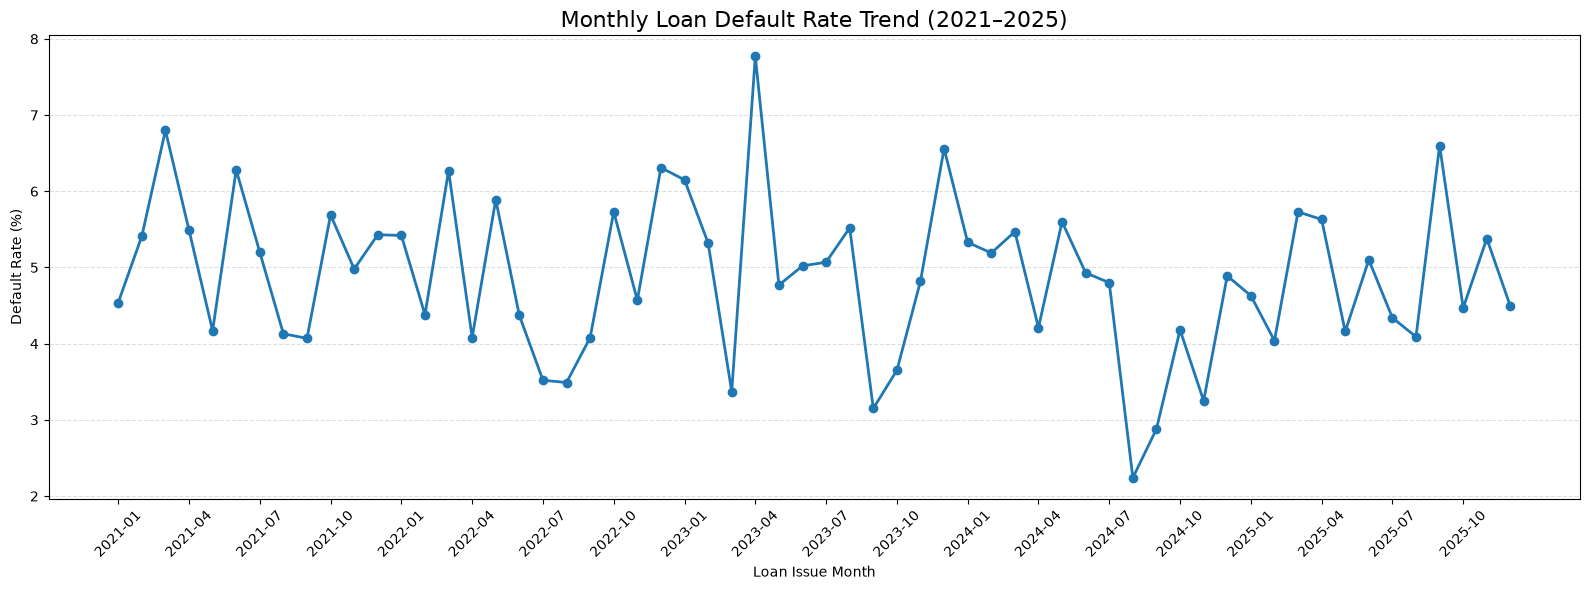

In [91]:
plt.figure(figsize=(16, 6))
plt.plot(
    monthly_analysis.index.astype(str),
    monthly_analysis["default_rate_pct"],
    marker="o",
    linewidth=2)
plt.title("Monthly Loan Default Rate Trend (2021–2025)", fontsize=16)
plt.xlabel("Loan Issue Month")
plt.ylabel("Default Rate (%)")

plt.xticks(range(0, len(monthly_analysis), 3),monthly_analysis.index.astype(str)[::3],rotation=45)
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

In [93]:
bins = [0, 500000, 1000000, 2000000, float("inf")]

labels = [
    "Low Income",
    "Lower-Middle Income",
    "Upper-Middle Income",
    "High Income"
]

credit_risk_df["income_group"] = pd.cut(
    credit_risk_df["annual_income"],
    bins=bins,
    labels=labels,
    include_lowest=True
)

credit_risk_df[["annual_income", "income_group"]].head()

,annual_income,income_group
0,597714.0,Lower-Middle Income
1,NaN,NaN
2,486474.0,Low Income
3,751936.0,Lower-Middle Income
4,717472.0,Lower-Middle Income


In [94]:
income_analysis = credit_risk_df.groupby(
    "income_group", observed=False
).agg(
    total_loans=("default_flag", "count"),
    defaulted_loans=("default_flag", "sum")
)

income_analysis["default_rate_pct"] = (income_analysis["defaulted_loans"]/ income_analysis["total_loans"] * 100).round(2)
income_analysis

,total_loans,defaulted_loans,default_rate_pct
income_group,,,
Low Income,6747,406,6.02
Lower-Middle Income,15194,727,4.78
Upper-Middle Income,7303,295,4.04
High Income,684,34,4.97


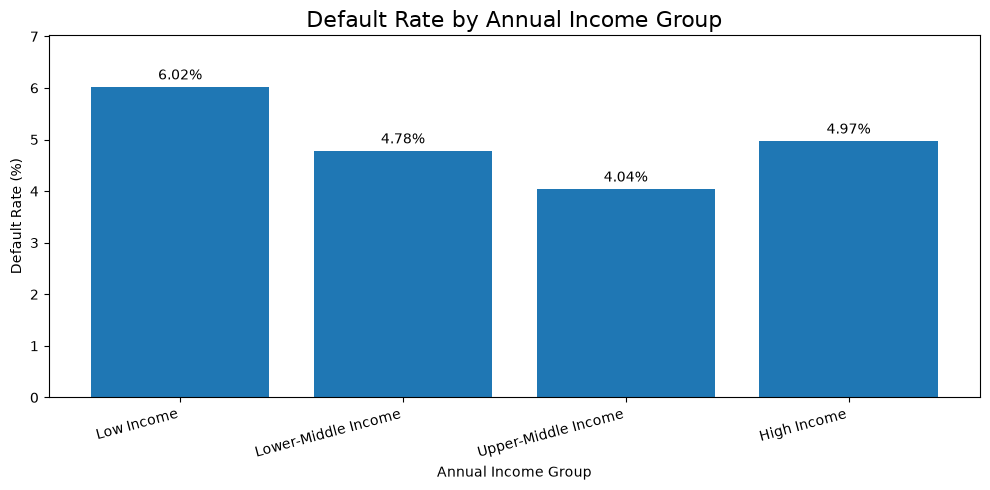

In [95]:
plt.figure(figsize=(10, 5))
bars = plt.bar(
    income_analysis.index.astype(str),
    income_analysis["default_rate_pct"])

plt.title("Default Rate by Annual Income Group", fontsize=16)
plt.xlabel("Annual Income Group")
plt.ylabel("Default Rate (%)")

plt.bar_label(bars, fmt="%.2f%%", padding=3)

plt.ylim(0, income_analysis["default_rate_pct"].max() + 1)
plt.xticks(rotation=15, ha="right")
plt.tight_layout()
plt.show()

### Key Findings

The analysis reveals a relationship between annual income and loan default rates across the four income groups.

* **Low-income borrowers** have the highest default rate at **6.02%**, based on 6,747 loans and 406 defaults.
* **Upper-middle-income borrowers** have the lowest default rate at **4.04%**, based on 7,303 loans and 295 defaults.
* The low-income group's default rate is approximately **1.49 times** that of the upper-middle-income group.
* **Lower-middle-income borrowers** represent the largest segment, with 15,194 loans and a default rate of 4.78%.
* The high-income group has a default rate of 4.97%, higher than the upper-middle-income group's rate. However, it contains only 684 loans,
so this result should be interpreted cautiously.

**Conclusion:** Lower income is associated with a higher default rate in this portfolio, but the pattern is not strictly linear.
    Income should therefore be evaluated alongside credit score, debt-to-income ratio, and repayment history rather than used as 
    a standalone indicator of creditworthiness.



 ### Recommended Actions

1. **Strengthen Affordability Checks:** Evaluate monthly repayment obligations relative to verified income,
     especially for borrowers in the low-income segment.

2. **Use Risk-Based Loan Assessments:** Combine income with credit score, debt-to-income ratio, 
    existing obligations, and delinquency history when assessing applications.

3. **Review High-Income Borrowers Carefully:** Investigate why the high-income group has a 4.97% default rate, 
    rather than assuming higher income automatically means lower risk.

4. **Monitor Portfolio Performance by Income Segment:** Track default rates and loan exposure regularly to identify segments 
   requiring further investigation or improved underwriting controls.

**Expected Business Value:** These measures can improve repayment-risk assessment, 
support responsible lending decisions, and help reduce avoidable defaults without unfairly excluding borrowers based solely on income.



In [98]:
credit_risk_df["loan_status"].value_counts(dropna=False)

loan_status
Current        16335
Fully Paid     12199
Default          920
Charged Off      546
Name: count, dtype: int64

In [99]:
pd.crosstab(
    credit_risk_df["loan_status"],
    credit_risk_df["default_flag"],
    margins=True
)

default_flag,0,1,All
loan_status,,,
Charged Off,0,546,546
Current,16335,0,16335
Default,0,920,920
Fully Paid,12199,0,12199
All,28534,1466,30000


The cross-tabulation confirms a perfect correspondence between loan status and the default flag in this dataset.All 920 loans
classified as "Default" and all 546 loans classified as "Charged Off" have `default_flag = 1`. Conversely, 
all Current and Fully Paid loans have `default_flag = 0`.

The overall default rate is 4.89% (1,466 out of 30,000 loans).

**Important implication:** Loan status should not be treated as an independent predictor of default in 
this dataset because it directly reflects the target variable. 
    Including it in a predictive model could cause target leakage and produce misleadingly strong results.


In [100]:
corr_columns = [
    "credit_score",
    "annual_income",
    "interest_rate",
    "debt_to_income_pct",
    "loan_amount",
    "delinquency_count",
    "default_flag"
]

corr_df = credit_risk_df[corr_columns]

corr_df.head()

,credit_score,annual_income,interest_rate,debt_to_income_pct,loan_amount,delinquency_count,default_flag
0,631,597714.0,0.00,25.6,286000.0,0,0
1,775,NaN,7.95,32.3,197300.0,0,0
2,659,486474.0,10.84,21.6,198800.0,0,0
3,697,751936.0,9.04,14.9,498500.0,0,0
4,688,717472.0,13.00,28.9,589200.0,0,0


In [101]:
corr_matrix = corr_df.corr()

corr_matrix.round(2)

,credit_score,annual_income,interest_rate,debt_to_income_pct,loan_amount,delinquency_count,default_flag
credit_score,1.00,0.14,-0.80,-0.14,-0.00,-0.20,-0.16
annual_income,0.14,1.00,-0.11,-0.09,0.00,-0.04,-0.02
interest_rate,-0.80,-0.11,1.00,0.23,0.01,0.20,0.15
debt_to_income_pct,-0.14,-0.09,0.23,1.00,0.00,0.12,0.08
loan_amount,-0.00,0.00,0.01,0.00,1.00,-0.00,-0.00
delinquency_count,-0.20,-0.04,0.20,0.12,-0.00,1.00,0.39
default_flag,-0.16,-0.02,0.15,0.08,-0.00,0.39,1.00


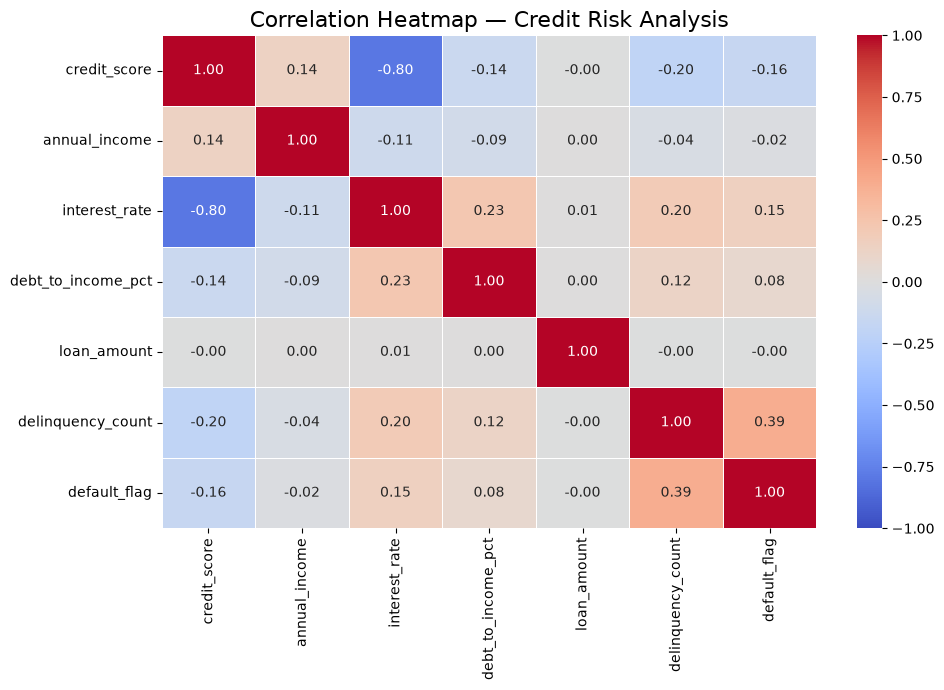

In [102]:
corr_matrix = corr_df.corr()
plt.figure(figsize=(10, 7))
sns.heatmap(
    corr_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5,
    vmin=-1,
    vmax=1
)

plt.title("Correlation Heatmap — Credit Risk Analysis", fontsize=16)
plt.tight_layout()
plt.show()

              ============================= FINAL SUMMERY OF THIS ANALSIS =============================
 #Credit Risk & Loan Default Analysis

## Final Exploratory Data Analysis (EDA)

### 1. Project Overview

The objective of this project is to analyze loan performance, identify borrower characteristics associated with loan defaults, 
and uncover potential credit risk patterns. The analysis uses customer and loan data combined into a dataset of **30,000 loan records**.

### 2. Key Findings

* **Overall Default Rate:** 1,466 out of 30,000 loans were flagged as defaults, representing an overall default rate of **4.89%**.
* **Credit Score:** Borrowers with poor credit scores had a default rate of **13.05%**, compared with **2.26%** for borrowers with good credit scores.
* **Interest Rate:** Loans with interest rates of 15%–20% had a default rate of **16.28%**, compared with **2.72%** for loans below 10%.
* **Debt-to-Income Ratio (DTI):** Borrowers with a DTI above 50% had a default rate of **9.63%**, compared with **2.82%** for borrowers with a DTI of 20% or less.
* **Delinquency History:** Borrowers with three or more delinquencies had a default rate of **59.08%**, while borrowers with no delinquencies had a rate of **1.34%**.
* **Employment Type:** Contract workers had the highest default rate at **6.56%**, while salaried borrowers had the lowest rate at **4.37%**.
* **Annual Income:** Low-income borrowers had a default rate of **6.02%**, compared with **4.04%** for upper-middle-income borrowers.
* **Loan Purpose:** Small Business loans had the highest default rate at **5.65%**. Debt Consolidation loans accounted for the largest number of loans and defaults.
* **Age and Customer Tenure:** Default rates varied relatively little across age and customer-tenure groups, suggesting that these factors alone may offer limited insight into default risk.
* **Loan Status Validation:** The `loan_status` field directly corresponds to `default_flag` in this dataset. It should not be treated as an independent predictor of default without further investigation.

### 3. Conclusion

The EDA indicates that credit score, delinquency history, debt-to-income ratio, and interest rate are important variables to investigate when assessing loan default risk. Income and employment type may provide additional context, while age and customer tenure show comparatively smaller differences in default rates.
These findings represent associations in the observed data and do not establish causation. Further analysis is needed before using these patterns to make lending decisions.


  ================================= Business Recommendations =================================
## Business Recommendations

1. **Strengthen Credit Risk Assessment:** Give particular attention to credit score, previous delinquencies, and DTI when assessing borrower repayment risk.

2. **Improve Affordability Checks:** Evaluate borrowers' income stability and existing financial obligations before approving loans, rather than relying on income alone.

3. **Monitor High-Risk Loan Segments:** Review Small Business loans and loans with higher interest rates to understand their default patterns and identify opportunities to improve underwriting.

4. **Build a Risk Monitoring Dashboard:** Track overall default rate, default rates by borrower segment, loan exposure, and monthly trends to support ongoing portfolio monitoring


In [104]:
credit_risk_df.to_csv("credit_risk_cleaned.csv", index=False)